# Парсинг вакансій та аналіз навичок Data Scientist: Від збору даних до інсайтів з українського тексту

У цьому уроці-майстер-класі ми зробимо один з типів Data Science проєктів, які зустрічаються в індустрії і який буде класним доповненням в Ваше портфоліо. 

**Задача:** Виявити, які конкретні навички прямо зараз є актуальними на ринку в обраному напрямі. В нашому випадку, Data Science.

Для цього нам необхідно
- Зібрати актуальні вакансії;
- Проаналізувати текст вакансій;
- Виявити навички в вакансіях;
- Зробити висновки.

В ході виконання завдання ми
- навчимося автоматично збирати дані з вебсайту (ця процедера називається "парсинг") за допомогою бібліотеки `selenium`;
- побудуємо візуалізацію WordCloud для аналізу текстів;
- познайомимось з поняттям n-грамів в обробці природньої мови;
- використаємо ChatGPT за АРІ аби "почистити" тексти вакансії від зайвої інформації і проставити лейбли для вакансій.

Збирати актуальні вакансії будемо в сфері Data Science з ресурсу DOU.ua, працюватимемо з українською та англіською мовами, та в результаті визначимо, які навички є найбільш затребуваними для фахівців з даних (data scientist).

В цьому уроці ми будемо працювати з web-сторінками, тому нам треба познайомитись з поняттям HTML.

## Коротке інтро, що таке HTML

**HTML (HyperText Markup Language)** — це стандартна мова розмітки, яка використовується для створення та структурування контенту вебсторінок в інтернеті. Вона дозволяє розмічати текст і додавати до нього різні елементи, такі як заголовки, абзаци, зображення, посилання, форми тощо.

Основні поняття HTML:

1. **Теги:**  
   HTML використовує теги для позначення різних елементів сторінки. Теги обмежуються кутовими дужками (`< >`) і зазвичай мають початковий і завершальний вигляд, наприклад:
   ```html
   <p>Це абзац тексту.</p>
   ```
   Деякі теги можуть бути самозакритими, наприклад, для зображень:
   ```html
   <img src="image.jpg" alt="Опис зображення" />
   ```

2. **Атрибути:**  
   Теги можуть містити атрибути, які надають додаткову інформацію про елемент. Наприклад, атрибут `src` вказує на джерело зображення, а `alt` описує його.
   ```html
   <img src="logo.png" alt="Логотип компанії" />
   ```

3. **Елементи:**  
   Елемент HTML складається з відкриваючого тегу, контенту та закриваючого тегу. Елементи можуть містити текст або інші елементи (вкладені елементи).
   ```html
   <h1>Заголовок сторінки</h1>
   ```

4. **Документна структура:**  
   Типовий HTML-документ має структуру з таких основних елементів:
   - `<!DOCTYPE html>` — вказує на тип документа.
   - `<html>` — кореневий тег документа.
   - `<head>` — містить метадані сторінки (стилі, метаінформація, скрипти).
   - `<body>` — містить видимий контент сторінки (текст, зображення, форми тощо).

   Наприклад:
   ```html
   <!DOCTYPE html>
   <html lang="uk">
     <head>
       <meta charset="UTF-8">
       <title>Назва сторінки</title>
     </head>
     <body>
       <h1>Вітаємо на нашому сайті!</h1>
       <p>Це перший абзац на сторінці.</p>
     </body>
   </html>
   ```

**Основна функція HTML** — це визначення структури і зовнішнього вигляду вебсторінки, яка потім відображається браузером. А от для додавання стилів (CSS) або інтерактивності (JavaScript) використовуються інші мови.

In [1]:
!pip install selenium

   ---------------------------------------- 0.0/11.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.8 MB ? eta -:--:--
    --------------------------------------- 0.3/11.8 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.8 MB 1.9 MB/s eta 0:00:06
   ----- ---------------------------------- 1.6/11.8 MB 2.4 MB/s eta 0:00:05
   ------- -------------------------------- 2.1/11.8 MB 2.6 MB/s eta 0:00:04
   -------- ------------------------------- 2.6/11.8 MB 2.6 MB/s eta 0:00:04
   ---------- ----------------------------- 3.1/11.8 MB 2.6 MB/s eta 0:00:04
   ------------ --------------------------- 3.7/11.8 MB 2.7 MB/s eta 0:00:04
   --------------- ------------------------ 4.5/11.8 MB 2.7 MB/s eta 0:00:03
   ---------------- ----------------------- 5.0/11.8 MB 2.7 MB/s eta 0:00:03
   ----------------- ---------------------- 5.2/11.8 MB 2.7 MB/s eta 0:00:03
   ------------------ -----

In [5]:
!pip install chromedriver-autoinstaller

In [7]:
from selenium import webdriver
from bs4 import BeautifulSoup
import pandas as pd
import time
import requests
from tqdm import tqdm

#import chromedriver_autoinstaller as chromedriver
#chromedriver.install()

from selenium.webdriver.common.by import By

Зараз ми будемо парсити сторінку з вакансіями для Data Science, використовуючи бібліотеку Selenium. Першим кроком є відкриття вебсторінки, яка містить ці вакансії, за допомогою вебдрайвера Chrome. Для цього ми ініціалізуємо драйвер і вказуємо йому відкрити URL-адресу сторінки з вакансіями на DOU. 



In [13]:
driver = webdriver.Chrome()

driver.get('https://jobs.dou.ua/vacancies/?category=Data+Science')


На цьому етапі наш драйвер завантажує HTML-код сторінки, що дає нам можливість витягувати з нього необхідну інформацію. Далі ми будемо шукати конкретні елементи на сторінці, такі як заголовки вакансій, вимоги та інші деталі, і зберігати їх для подальшого аналізу.

Ми реалізуємо механізм для автоматичного завантаження більшої кількості вакансій на сторінці. Більшість сайтів, включаючи DOU, не показують всі вакансії одразу, тому користувачу потрібно натискати кнопку "Завантажити більше", щоб відобразити додаткові вакансії. Ми імітуємо дії користувача з `selenium`. І для цього робимо цикл:
1. У кожній ітерації циклу ми шукаємо елемент на сторінці, який відповідає кнопці для завантаження додаткових вакансій.
2. Після кожного кліка ми додаємо паузу в 3 секунди, щоб дати сторінці час на завантаження нових вакансій.
3. Якщо на сторінці більше немає кнопки "Завантажити більше" або виникає інша помилка (наприклад, елемент не знайдено), виконання програми перехоплює виключення, виводить повідомлення про завершення і виходить з циклу. 

In [14]:
while True:
    try:
        driver.find_element(By.CSS_SELECTOR, 'div.more-btn a').click()
        time.sleep(3)
    except Exception as ex:
        print(ex)
        print('End.')
        break

Message: element not interactable
  (Session info: chrome=152.0.7977.83); For documentation on this error, please visit: https://www.selenium.dev/documentation/webdriver/troubleshooting/errors#elementnotinteractableexception
Stacktrace:
	chromedriver!GetHandleVerifier [0x7ff73585e035+5745]
	chromedriver!(No symbol) [0x7ff735786a90]
	chromedriver!(No symbol) [0x7ff7355b5b66]
	chromedriver!(No symbol) [0x7ff735612244]
	chromedriver!(No symbol) [0x7ff735604d88]
	chromedriver!(No symbol) [0x7ff7356395ca]
	chromedriver!(No symbol) [0x7ff735604606]
	chromedriver!(No symbol) [0x7ff73565e502]
	chromedriver!(No symbol) [0x7ff735602e4b]
	chromedriver!(No symbol) [0x7ff735603d83]
	chromedriver!GetHandleVerifier [0x7ff735c72f8b+41a69b]
	chromedriver!GetHandleVerifier [0x7ff735ca0132+447842]
	chromedriver!GetHandleVerifier [0x7ff735c93e7e+43b58e]
	chromedriver!GetHandleVerifier [0x7ff735953f5e+fb66e]
	chromedriver!(No symbol) [0x7ff73579419c]
	chromedriver!(No symbol) [0x7ff73578fdd4]
	chromedriver

На цьому етапі ми провантажили весь перелік вакансій обраної категорії і можемо завантажити їх у змінну.

Для зручності подальшої роботи ми використовуємо бібліотеку `BeautifulSoup`, яка має багато різного фукнціоналу для роботи з контентом в форматі html.

У даному випадку, `BeautifulSoup` виконує наступні дії:

1. **Парсинг HTML-контенту:**  
   Коли ми викликаємо `BeautifulSoup(content)`, бібліотека обробляє весь HTML-код, отриманий від вебдрайвера (`driver.page_source`). Вона перетворює його у зручний для роботи формат дерева, що дозволяє легко шукати та витягувати елементи сторінки.

2. **Створення об'єкта для подальшого аналізу:**  
   `soup` — це об'єкт, який містить всю структуру HTML. З його допомогою можна виконувати подальші операції: знаходити конкретні елементи сторінки, витягувати текстові дані, аналізувати посилання, таблиці, списки тощо.

Завдяки цьому ми можемо переходити до пошуку та витягування необхідної інформації зі сторінки, наприклад, посилань на вакансії, заголовків вакансій, вимог, імен компаній тощо.

In [15]:
content = driver.page_source
soup = BeautifulSoup(content)

In [8]:
# soup

In [ ]:
# driver.close()

У нас зараз вивантажена сторінка з усіма вакансіями і ми хочемо взяти посилання кожної з вакансій аби потім провантажити сторінки з описами вакансій. Для цього пишемо код, який шукає в html сторінки посилання на вакансії.

In [17]:
vac_list = soup.find_all('a',href=True, attrs={'class':'vt'})
project_href = [i['href'] for i in vac_list]

І такий результат ми отримали:

In [18]:
project_href

['https://jobs.dou.ua/companies/sombra/vacancies/371869/?from=list_hot',
 'https://jobs.dou.ua/companies/artellence/vacancies/376247/',
 'https://jobs.dou.ua/companies/smart-business/vacancies/372582/',
 'https://jobs.dou.ua/companies/digis/vacancies/376059/',
 'https://jobs.dou.ua/companies/grid-dynamics/vacancies/375977/',
 'https://jobs.dou.ua/companies/megogonet-/vacancies/314045/',
 'https://jobs.dou.ua/companies/gur-mo/vacancies/357943/',
 'https://jobs.dou.ua/companies/xenoss/vacancies/375846/',
 'https://jobs.dou.ua/companies/omd-systems/vacancies/357726/',
 'https://jobs.dou.ua/companies/insart/vacancies/375671/',
 'https://jobs.dou.ua/companies/fit4me/vacancies/375639/',
 'https://jobs.dou.ua/companies/obrio/vacancies/362752/',
 'https://jobs.dou.ua/companies/softelegance/vacancies/375482/',
 'https://jobs.dou.ua/companies/comfy/vacancies/343719/',
 'https://jobs.dou.ua/companies/quantum/vacancies/375425/',
 'https://jobs.dou.ua/companies/nove8/vacancies/375402/',
 'https://j

Тепер нам треба завантажити кожне з цих посилань та взяти з них текст вакансій.

In [19]:
headers={"User-Agent": "HTTPie/3.1.0"}

In [20]:
vacs = {
    'link': [],
    'name': [],
    'desc': []
}
for link in tqdm(project_href):
    page = requests.get(link, headers=headers)
    soup = BeautifulSoup(page.content, "html.parser")
    vacs['link'].append(link)
    vacs['name'].append(soup.title.text)
    vacs['desc'].append(soup.select('div.vacancy-section')[0].text)
    time.sleep(1)

100%|██████████| 45/45 [01:13<00:00,  1.64s/it]


In [21]:
len(vacs['link'])

45

Далі вже все просто: записуємо результат в датафрейм і використовуємо для подальших цілей.

In [22]:
df = pd.DataFrame(vacs)

In [23]:
df.head()

,link,name,desc
0,https://jobs.dou.ua/companies/sombra/vacancies...,Middle/Senior ML Engineer (Data Science) в Som...,\nWe are looking for a Middle/Senior ML Engine...
1,https://jobs.dou.ua/companies/artellence/vacan...,Strong junior Machine learning engineer в Arte...,\nПРО КОМПАНІЮDriving the age of AI. Наша мета...
2,https://jobs.dou.ua/companies/smart-business/v...,Senior Data Science / AI Engineer (Azure) в SM...,\nSMART business — міжнародна IT-компанія з оф...
3,https://jobs.dou.ua/companies/digis/vacancies/...,"Trainee Data Scientist в Digis, віддалено | DOU",\nAbout the CompanyWe are a European IT compan...
4,https://jobs.dou.ua/companies/grid-dynamics/va...,"Data Scientist в Grid Dynamics, Київ, Харків, ...",\nAbout the RoleWe are looking for a hands-on ...


In [24]:
df.to_csv('data_science_vacs.csv', index=False)

In [25]:
print(df.desc.loc[1])


ПРО КОМПАНІЮDriving the age of AI. Наша мета — наближати еру штучного інтелекту, а сфера, в якій ми долучилися до AI-революції — OSINT (розвідка за відкритими даними).Створюємо власні потужні технології. Біометрична ідентифікація, аналіз об’єктів на фото, дослідження цифрового сліду в мережі, AI-агенти — наші рішення, які застосовуються в розслідувальній діяльності правоохоронних органів, при оцінці потенційно ризикових зв’язків в державних тендерах, та найбільшими компаніями України для захисту від зовнішніх й внутрішніх загроз.Робимо суспільний внесок. Організовуємо власні OSINT-конференції та хакатони міжнародного рівня, співпрацюємо з DefenseTech об’єднанням Brave1, МінЦифрою та програмами ЄС для пришвидшення розвитку передових технологій в Україні.Детальніше про Artellence. Сайт: artellence.com, відгуки співробітників: jobs.dou.ua/companies/artellence/reviews.ПРО КУЛЬТУРУСтворюємо те, що має значення. Наші технології сприяють підвищенню прозорості та безпеки України й українськог

## Debug data collection

Цю секцію я використовувала для дебагінгу збору даних. Структура сторінок може змінватись, тож завжди корисно спочатку налаштувати все на одній сторінці.

In [ ]:
link = project_href[0]

In [ ]:
page = requests.get(link, headers=headers)
soup = BeautifulSoup(page.content, "html.parser")

In [ ]:
link

In [ ]:
extracted = soup.select('div.vacancy-section')
# 'vacancy-section']

In [ ]:
print(extracted[0].text)

In [ ]:
soup.title

# Visualize

Наша задача зараз - зрозуміти, що хочуть бачити в Data Scientists зараз. Для цього давайте візуалізуємо дані в вигляді WordCloud.

## WordCloud
**WordCloud (хмара слів)** — це візуалізація текстових даних, яка показує найбільш часто використовувані слова в тексті. У такій візуалізації кожне слово має свій розмір, що відповідає його частоті в тексті: чим частіше слово зустрічається, тим більшим шрифтом воно відображається в хмарі слів. Хмара слів часто використовується в аналізі великих текстових корпусів, таких як новини, соціальні медіа, наукові публікації та інші джерела, щоб швидко зрозуміти ключові теми.

Основні характеристики WordCloud:
1. **Частотність слів:**  
   Найбільш поширені слова у тексті займають більше місця в хмарі і відображаються великим шрифтом, менш поширені — меншим.
   
2. **Візуальна інтерпретація:**  
   Хмара слів дозволяє швидко зрозуміти основні теми або ключові поняття в тексті, оскільки найважливіші терміни виражені візуально.
   
3. **Обробка тексту:**  
   Перед створенням хмари слів, текст зазвичай проходить обробку: видаляються стоп-слова (наприклад, "і", "в", "на"), знаки пунктуації, числа та інші незначні елементи.

### Приклад:
Якщо ви аналізуєте набір вакансій для Data Scientists, хмара слів може показати найбільш важливі навички та інструменти, такі як "Python", "Machine Learning", "Data", "SQL" тощо, допомагаючи виявити ключові вимоги до кандидатів.

Для створення хмари слів можна використовувати бібліотеку `WordCloud`:

In [26]:
!pip install wordcloud

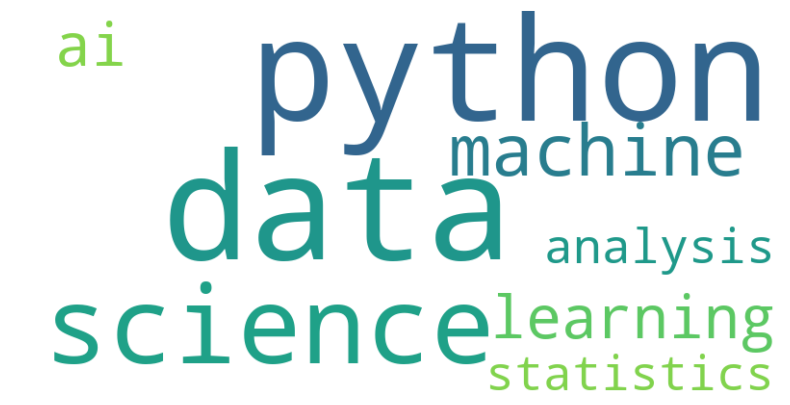

In [27]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Текст для аналізу
text = "data science python machine learning ai statistics python analysis data"

# Створення хмари слів
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)

# Відображення хмари слів
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

Тепер побудуємо WordCloud для нашого набору даних з описами вакансій.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from nltk.corpus import stopwords
from wordcloud import WordCloud

In [9]:
df = pd.read_csv('data_science_vacs.csv')

Давайте видалимо стоп-слова. Тут у нас зустрічаються українські тексти в тому числі, і завантажити стопслова для української ми можемо звідси: https://github.com/skupriienko/Ukrainian-Stopwords

In [10]:
stopwords_ua = pd.read_csv("stopwords_ua.txt", header=None, names=['stopwords'])
stopwords_ua = list(stopwords_ua.stopwords)

In [11]:
stopwords_list = stopwords_ua + stopwords.words('english')

In [12]:
text = '\n'.join(df.desc.tolist())

In [13]:
len(text)

168084

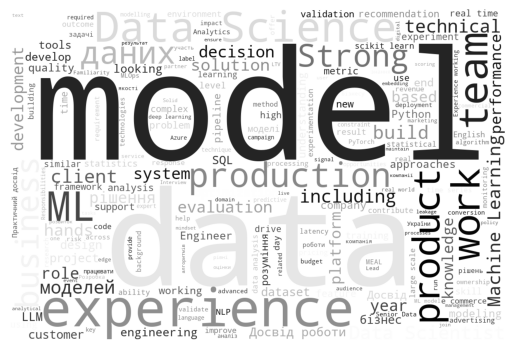

In [14]:
def create_wordcloud(text, stopwords_list):
    wc = WordCloud(
        background_color='white', 
        colormap = 'binary', 
        stopwords = stopwords_list, 
        width = 1200, 
        height = 800).generate(text)
    plt.axis("off")
    plt.imshow(wc)

create_wordcloud(text, stopwords_list)

Непогано, але можна краще.
Ця хмара слів частково відображає основні поняття, які можуть бути корисними для Data Scientist, такі як "Python", "machine learning", "NLP", "data", "model", "experience", "team". Вона дає загальне уявлення про те, що є важливим у вакансіях, але не забезпечує точного фокусу на конкретних навичках, що нам було б найцікавіше знати в такому аналізі.

Проблеми з поточною хмарою слів:
1. **Невизначеність ключових слів:**  
   У хмарі з'являються слова, які не відносяться безпосередньо до навичок, наприклад, "company", "team", "work", "experience", "product". Ці слова є занадто загальними і не дають корисної інформації про технічні чи аналітичні навички, які потребує Data Scientist.

2. **Мікс термінів:**  
   Хмара слів містить як технічні терміни (наприклад, "Python", "SQL", "machine learning"), так і загальні терміни, що можуть бути частиною опису вакансії, але не є навичками ("company", "development", "team").

   
Давайте проведемо додаткову обробку аби витягнути саме навички.

## Extract skills

Скористаємось chatGPT аби з вакансії прибрати опис вакансії і сконцентруватись на вимогах до кандидата. 

Завантажуємо для початку наш API KEY.

In [15]:
from openai import OpenAI
import json
import os

creds = json.load(open('chatgpt_4_openai_creds.json'))
os.environ['OPENAI_API_KEY'] = creds['OPENAI_API_KEY']
client = OpenAI()

In [16]:
creds.keys()

dict_keys(['OPENAI_API_KEY', 'OPENAI_CHAT_MODEL_NAME'])

```
{
    "OPENAI_API_KEY": "....",
    "OPENAI_CHAT_MODEL_NAME": "gpt-4o-mini"
}
```

In [17]:
openai_model_used = 'gpt-4o-mini'
max_tokens = 4096

def generate_messages(system_content, user_content):
    return [
        {
            "role": "system",
            "content": system_content            
        },
        {
            "role": "user",
            "content":  user_content
        }
    ]

def get_openai_response(messages, temperature=0, max_tokens=max_tokens, top_p=1):
    client = OpenAI()
    return client.chat.completions.create(
        model=openai_model_used,
        messages=messages,
        temperature=temperature,
        # max_tokens=max_tokens,
        top_p=top_p
    )

In [18]:
print(df.desc.loc[0])


We are looking for a Middle/Senior ML Engineer to turn loosely framed business problems into reliable, actionable models for a proprietary trading platform that connects traders with funding opportunities. You will work in a high-load, low-latency environment processing millions of events in real time, taking ownership from problem framing and feature engineering through model testing and business-ready results.Required for this roleSolid grounding in machine learning theory, with the ability to explain and justify modeling decisions beyond library calls.Experience in building supervised (churn, customer decision) and unsupervised (clustering, identifying anomalies) risk modelsPractical experience with XGBoost or other gradient boosting methods (GBM).Understanding of logistic regression and its practical application to business problems.Experience building causal models (A/B testing, control groups, uplift modeling) and identifying why something happenedHands-on experience with Python

Задамо промпт, який дозволить нам прибрати все, що не стосується безпосередньо опису навичок кандидата.

In [19]:
prompt = """
You are provided with a technical vacancy description either in English or in Ukrainian. 
Extract only skills required for a candidate and the responsibilities. Return the extracted part 
as a plain text.
Vacancy:
{}
"""
system_content = ''

In [20]:
generate_messages(system_content, prompt.format(df.desc.loc[0]))

[{'role': 'system', 'content': ''},
 {'role': 'user',
  'content': '\nYou are provided with a technical vacancy description either in English or in Ukrainian. \nExtract only skills required for a candidate and the responsibilities. Return the extracted part \nas a plain text.\nVacancy:\n\nWe\xa0are looking for a\xa0Middle/Senior ML\xa0Engineer to\xa0turn loosely framed business problems into reliable, actionable models for a\xa0proprietary trading platform that connects traders with funding opportunities. You will work in\xa0a\xa0high-load, low-latency environment processing millions of\xa0events in\xa0real time, taking ownership from problem framing and feature engineering through model testing and business-ready results.Required for this roleSolid grounding in\xa0machine learning theory, with the ability to\xa0explain and justify modeling decisions beyond library calls.Experience in\xa0building supervised (churn, customer decision) and unsupervised (clustering, identifying anomalies)

In [21]:
response = get_openai_response(
    generate_messages(system_content, prompt.format(df.desc.loc[0]))
)

In [22]:
response

ChatCompletion(id='chatcmpl-EYG68moZ4IvE2NHXSUBmg4eOfKnWn', choices=[Choice(finish_reason='stop', index=0, logprobs=None, message=ChatCompletionMessage(content='**Required Skills:**\n- Solid grounding in machine learning theory\n- Experience in building supervised and unsupervised risk models\n- Practical experience with XGBoost or other gradient boosting methods\n- Understanding of logistic regression and its practical application\n- Experience building causal models (A/B testing, control groups, uplift modeling)\n- Hands-on experience with Python, NumPy, SciPy, Pandas, and Scikit-learn\n- Experience working with PySpark, including MLlib\n- Experience with survival analysis or time-to-event modeling\n- Knowledge of hierarchical modeling methods\n- Experience using MLflow or comparable experiment and model tracking tools\n- Strong communication skills and comfort with ambiguity\n- Fluent spoken English (B2)\n\n**Responsibilities:**\n- Take loosely framed business problems and develop a

In [44]:
response_text = response.model_dump()['choices'][0]['message']['content']

In [45]:
print(response_text)

**Responsibilities:**
- Become an expert on TransVoyant CDI™ Platform solutions and how they solve pressing customer challenges within Supply Chain and related arenas.
- Identify, retrieve, manipulate, relate, and exploit multiple TransVoyant structured and unstructured data sets from various sources (e.g., tweets, live aircraft, forecast weather), including building or generating new data sets as appropriate.
- Create methods, models, and algorithms to understand the meaning of streaming live data, translating it into insightful predictive output for customer applications and data products.
- Educate internal staff (e.g., development, sales, marketing) on how data science and resulting predictions can be productized for key industry verticals.
- Keep up to date on competitive solutions, products, and services.

**Skills Required:**
- 2+ years of cloud-based data parsing and analysis, data manipulation and transformation, and visualization experience.
- Programming and scripting experi

In [36]:
# process all vacancies

def get_skills(vacancy):
    return get_openai_response(generate_messages(system_content, prompt.format(vacancy)))

df['skills'] = df.desc.apply(get_skills)

In [37]:
df['skills_text'] = df.skills.apply(lambda x: x.model_dump()['choices'][0]['message']['content'])

In [38]:
print(df['desc'].loc[1])


ПРО КОМПАНІЮDriving the age of AI. Наша мета — наближати еру штучного інтелекту, а сфера, в якій ми долучилися до AI-революції — OSINT (розвідка за відкритими даними).Створюємо власні потужні технології. Біометрична ідентифікація, аналіз об’єктів на фото, дослідження цифрового сліду в мережі, AI-агенти — наші рішення, які застосовуються в розслідувальній діяльності правоохоронних органів, при оцінці потенційно ризикових зв’язків в державних тендерах, та найбільшими компаніями України для захисту від зовнішніх й внутрішніх загроз.Робимо суспільний внесок. Організовуємо власні OSINT-конференції та хакатони міжнародного рівня, співпрацюємо з DefenseTech об’єднанням Brave1, МінЦифрою та програмами ЄС для пришвидшення розвитку передових технологій в Україні.Детальніше про Artellence. Сайт: artellence.com, відгуки співробітників: jobs.dou.ua/companies/artellence/reviews.ПРО КУЛЬТУРУСтворюємо те, що має значення. Наші технології сприяють підвищенню прозорості та безпеки України й українськог

In [39]:
print(df['skills_text'].loc[1])

**Skills Required:**
- Experience in Data Science/Machine Learning (DS/MLE) for at least 2 years
- Mathematical background: higher education in mathematics (preferably from KPI IPSA, MechMat Shevchenko, etc.), ideally with Olympiad experience
- Deep knowledge of algorithms and data structures, strong understanding of OOP, and both theoretical and practical knowledge of machine learning and deep learning
- Practical experience in solving NLP and Tabular Data ML tasks
- High proficiency in Python, including experience with machine learning libraries and at least one deep learning framework (TensorFlow, Keras, PyTorch)
- Ability to write clean, maintainable, and efficient production-ready code
- Ability to transform business requirements into technical tasks for ML solutions
- Experience in feature engineering
- Experience with Git and Docker
- Experience with databases (SQL/NoSQL) for data retrieval and preparation for models

**Responsibilities:**
- Improve the accuracy of current CV, N

In [40]:
df.to_csv('data_science_vacs_enriched.csv', index=False)
df = pd.read_csv('data_science_vacs_enriched.csv')

In [41]:
# df[['desc', 'skills_text']]

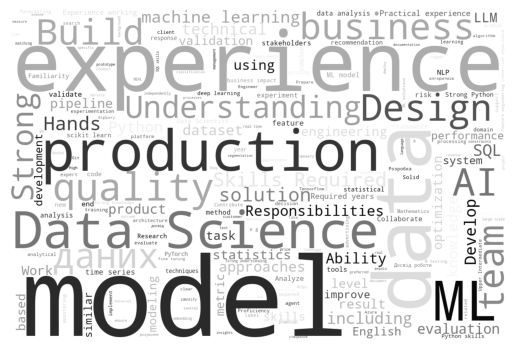

In [42]:
text = '\n'.join(df.skills_text.tolist())
create_wordcloud(text, stopwords_list)

Все ще виглядає як трошки не то. Давайте зробимо користувацький препроцесинг. 
А для початку познайомимось з поняттям n-grams.

## Що таке N-грами

**N-grams** — це послідовності з n елементів (зазвичай слів або символів), які використовуються в обробці природної мови (NLP) для аналізу тексту. N може бути будь-яким цілим числом і вказує кількість елементів у послідовності.

### Типи n-grams:
1. **Unigram (1-gram):**  
   Це окремі слова або символи в тексті. Наприклад, у реченні "I love Python", уніграми будуть:
   - I
   - love
   - Python

2. **Bigram (2-gram):**  
   Це послідовності з двох слів або символів. Для того ж речення "I love Python", біграми будуть:
   - I love
   - love Python

3. **Trigram (3-gram):**  
   Це послідовності з трьох слів або символів. У реченні "I love Python", тріграми будуть:
   - I love Python

4. **N-grams:**  
   Якщо n більше трьох, це можуть бути, наприклад, 4-grams, 5-grams тощо.

### Для чого використовують N-grams:
1. **Аналіз тексту:**  
   N-grams використовуються для виявлення частих словосполучень або шаблонів в тексті. Це особливо корисно для розуміння структури тексту або для аналізу мови.

2. **Моделювання мови:**  
   N-grams допомагають прогнозувати наступне слово в реченні на основі попередніх слів. Це ключовий підхід у задачах, таких як автозаповнення тексту чи машинний переклад.

3. **Класифікація тексту:**  
   N-grams часто використовуються як ознаки для моделювання текстової класифікації, наприклад, у задачах аналізу настроїв або виявлення спаму.

4. **Аналіз послідовностей:**  
   N-grams можуть використовуватись для аналізу біологічних послідовностей (ДНК) або інших форм послідовних даних.

### Приклад коду в Python з використанням `nltk` для генерації біграм:


In [26]:
import nltk
from nltk import ngrams

text = "I love Python programming"
tokens = nltk.word_tokenize(text)

# Генерація біграм
bigrams = list(ngrams(tokens, 2))
print(bigrams)

[('I', 'love'), ('love', 'Python'), ('Python', 'programming')]


Використаємо n-грами в нашому аналізі. В WordCloud за замовченням беруться до уваги unigrams and bigrams - можна в цьому переконатись в [сорс коді бібліотеки](https://github.com/amueller/word_cloud/blob/main/wordcloud/wordcloud.py#L598).

In [43]:
import nltk
from nltk import word_tokenize
from nltk.util import bigrams
from collections import Counter
import re

nltk.download('punkt') 

def clean_text(text):
    # Remove non-word characters
    text = re.sub(r'\W+', ' ', text).lower()
    # Tokenize text
    tokens = word_tokenize(text)
    # Remove stopwords
    stop_words = set(stopwords.words('english'))
    cleaned_tokens = [word for word in tokens if word not in stop_words]
    # Join cleaned tokens back into a string
    return ' '.join(cleaned_tokens)

tokens = word_tokenize(clean_text(text.lower()))  # Tokenize and convert to lower case
bigram_list = list(bigrams(tokens))
bigram_freq = Counter(bigram_list)



[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [44]:
bigram_freq_d = dict(bigram_freq)

In [45]:
bigram_freq_d = {' '.join(k):v for k, v in bigram_freq_d.items()}

In [46]:
bigram_df = pd.DataFrame(bigram_freq_d.items(), columns=['bigram', 'freq'])

In [47]:
bigram_df.sort_values(by = 'freq', ascending=False)[:30]

,bigram,freq
143,data science,44
140,skills required,31
4,machine learning,30
33,hands experience,24
13,practical experience,18
142,experience data,18
261,time series,17
41,experience working,16
254,years experience,16
493,ml models,15


In [48]:
df['contains llm'] = df.desc.str.lower().apply(lambda x: 'llm' in x or 'generative' in x)

In [49]:
df['contains neural'] = df.desc.str.lower().apply(lambda x: 'neural' in x or 'deep' in x)

In [50]:
df.to_csv('data_science_vacs_enriched.csv', index=False)

In [51]:
df['contains llm'].value_counts()

contains llm
False    36
True      9
Name: count, dtype: int64

In [52]:
df['contains neural'].value_counts()

contains neural
False    31
True     14
Name: count, dtype: int64

In [53]:
pd.options.display.max_columns = None
pd.options.display.max_rows = None
pd.options.display.max_colwidth = None

# df[df['contains llm']][['name','desc', 'link']]

In [55]:
# df[df['contains neural']][['name','desc', 'link']]